# Trabajo Práctico N° 3: SVM y Random Forest

- Año: 2026
- Materia: Minería de Datos
- Integrantes: Frank, Maximiliano; Winter, Federico

Recomendamos uno de 10 cultivos a partir de 16 variables de suelo y clima. El conjunto parte de un dataset de Kaggle ([fuente](https://www.kaggle.com/datasets/markjehan/global-crop-recommendation)), modificado para este trabajo según el enunciado. Todas las particiones, validaciones cruzadas y modelos usan random_state=13.

In [1]:
# Importo las librerías y fijo la semilla
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 13  # random_state de todas las particiones, validaciones cruzadas y modelos


# Defino una función que agrega "Figura n" debajo del gráfico
def numerar(n):
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.figtext(0.5, 0.01, f"Figura {n}", ha="center", va="bottom")


## 1. Preparación de datos

El archivo crop_recommendation_geo.csv tiene 50004 filas y 17 columnas (50005 líneas con el encabezado, que son las 50005 muestras que menciona el enunciado). La variable objetivo se llama clase en el CSV y Clase en el enunciado. Usamos los nombres del CSV: el enunciado escribe temp_mim_mensual donde el archivo dice temp_min_mensual.

| Variable | Qué representa | Tipo | Rol |
|---|---|---|---|
| N | Nitrógeno total en el suelo (0-30 cm) | Numérica continua | Predictora |
| P | Fósforo disponible para las plantas (Olsen) | Numérica continua | Predictora |
| exch_bases | Bases intercambiables totales (Ca + Mg + K + Na) de la capa superficial del suelo | Numérica continua | Predictora |
| ph | pH del suelo en agua (0-30 cm) | Numérica continua | Predictora |
| soc | Carbono orgánico del suelo (0-30 cm) | Numérica continua | Predictora |
| arcilla | Fracción arcillosa (0-30 cm) | Numérica continua | Predictora |
| arena | Fracción de arena (0-30 cm) | Numérica continua | Predictora |
| cec | Capacidad de intercambio catiónico | Numérica continua | Predictora |
| temperatura | Temperatura media anual del aire | Numérica continua | Predictora |
| temp_min_mensual | Temperatura media del mes más frío | Numérica continua | Predictora |
| temp_max_mensual | Temperatura media del mes más cálido | Numérica continua | Predictora |
| humedad | Humedad relativa media anual | Numérica continua | Predictora |
| lluvia | Precipitación anual | Numérica discreta | Predictora |
| estacionalidad_lluvias | Coeficiente de variación de la precipitación mensual (BIO15) | Numérica continua | Predictora |
| radiacion_solar | Radiación solar incidente media anual | Numérica continua | Predictora |
| elevacion | Altura sobre el nivel del mar | Numérica discreta | Predictora |
| clase | Cultivo recomendado (algodon, arroz, banana, cafe, coco, frijol, garbanzo, lenteja, maiz y manzana) | Categórica nominal | Objetivo |

Hipótesis: esperamos que P, soc, lluvia y elevacion tengan cola larga a la derecha, porque no pueden ser negativas.

In [2]:
# Leo el CSV con ";" como separador y "," como decimal
df = pd.read_csv("crop_recommendation_geo.csv", sep=";", decimal=",")
display(df.head())
df.info()


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
0,1.353,6.689,13.5,7.233,11.167,24.867,31.017,16.867,24.868,15.185,31.804,65.161,1148,126.689,19.228,96,arroz
1,1.855,11.072,16.9,6.083,15.583,37.217,25.750,15.933,23.829,16.888,29.372,83.058,1740,81.048,15.206,3,arroz
2,1.727,14.273,29.0,6.400,15.717,26.667,35.000,23.683,18.029,7.566,27.969,77.170,1108,65.502,11.994,316,arroz
3,1.442,7.527,3.0,6.283,18.067,36.700,27.300,19.083,18.042,6.620,28.075,78.908,1483,51.357,13.621,343,arroz
4,1.920,12.067,15.8,6.983,16.600,28.733,29.450,18.533,16.284,7.726,24.241,59.990,471,83.554,16.836,6,arroz


<class 'pandas.DataFrame'>
RangeIndex: 50004 entries, 0 to 50003
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       50004 non-null  float64
 1   P                       50004 non-null  float64
 2   exch_bases              50004 non-null  float64
 3   ph                      50003 non-null  float64
 4   soc                     50004 non-null  float64
 5   arcilla                 50004 non-null  float64
 6   arena                   50004 non-null  float64
 7   cec                     50003 non-null  float64
 8   temperatura             50004 non-null  float64
 9   temp_min_mensual        50004 non-null  float64
 10  temp_max_mensual        50004 non-null  float64
 11  humedad                 50003 non-null  float64
 12  lluvia                  50004 non-null  int64  
 13  estacionalidad_lluvias  50004 non-null  float64
 14  radiacion_solar         50004 non-null  float64
 

El CSV usa punto y coma como separador y coma como decimal, por eso la lectura necesita sep=";" y decimal=",". Sin el segundo, las columnas con decimales se leen como texto.

Con la lectura correcta, df tiene 16 predictoras numéricas (14 float y 2 enteras: lluvia y elevacion) y clase como texto. ph, cec y humedad tienen un nulo cada una.

In [3]:
# Reviso nulos, duplicados, descriptivas y asimetría de las variables predictoras
num_cols = df.columns.drop("clase")
print("Columnas con nulos:", df.isna().any().sum())
print("Valores nulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0].to_string())
print("Filas duplicadas:", df.duplicated().sum())
print("\nAsimetría de cada variable:")
print(df[num_cols].skew().round(2).to_string())
df.describe().T.round(2)


Columnas con nulos: 3
Valores nulos por columna:
ph         1
cec        1
humedad    1
Filas duplicadas: 198

Asimetría de cada variable:
N                         1.78
P                         3.90
exch_bases                0.84
ph                        0.13
soc                       4.74
arcilla                   0.16
arena                     0.54
cec                       0.95
temperatura              -0.79
temp_min_mensual         -0.85
temp_max_mensual         -0.29
humedad                  -0.32
lluvia                    1.25
estacionalidad_lluvias    0.43
radiacion_solar          -0.22
elevacion                 2.41


,count,mean,std,min,25%,50%,75%,max
N,50004.0,1.81,0.96,0.26,1.10,1.63,2.27,15.10
P,50004.0,10.31,11.11,0.00,3.68,6.67,12.89,180.00
exch_bases,50004.0,17.86,11.98,0.10,7.00,16.00,26.50,143.00
ph,50003.0,6.48,1.02,4.05,5.55,6.50,7.35,25.32
soc,50004.0,24.34,26.46,1.02,11.02,18.12,27.18,322.82
arcilla,50004.0,31.24,8.05,2.40,25.63,31.03,36.77,142.38
arena,50004.0,36.90,13.56,0.88,28.02,34.68,45.03,94.50
cec,50003.0,20.46,7.74,3.72,15.55,19.55,24.23,70.82
temperatura,50004.0,19.24,7.72,-7.38,14.22,21.96,25.79,44.63
temp_min_mensual,50004.0,11.91,12.63,-27.87,3.10,16.44,22.10,27.92


Hay 3 valores nulos (uno en ph, uno en cec y uno en humedad) y 198 filas duplicadas. Los máximos de tres variables salen del rango físico: ph llega a 25.32, humedad a 148.14 y arcilla a 142.38, y el pH no pasa de 14 y los porcentajes no pasan de 100.

La asimetría confirma la primera parte de la hipótesis: soc (4.74), P (3.90), elevacion (2.41), N (1.78) y lluvia (1.25) tienen cola derecha. ph (0.13) y arcilla (0.16) son casi simétricas.

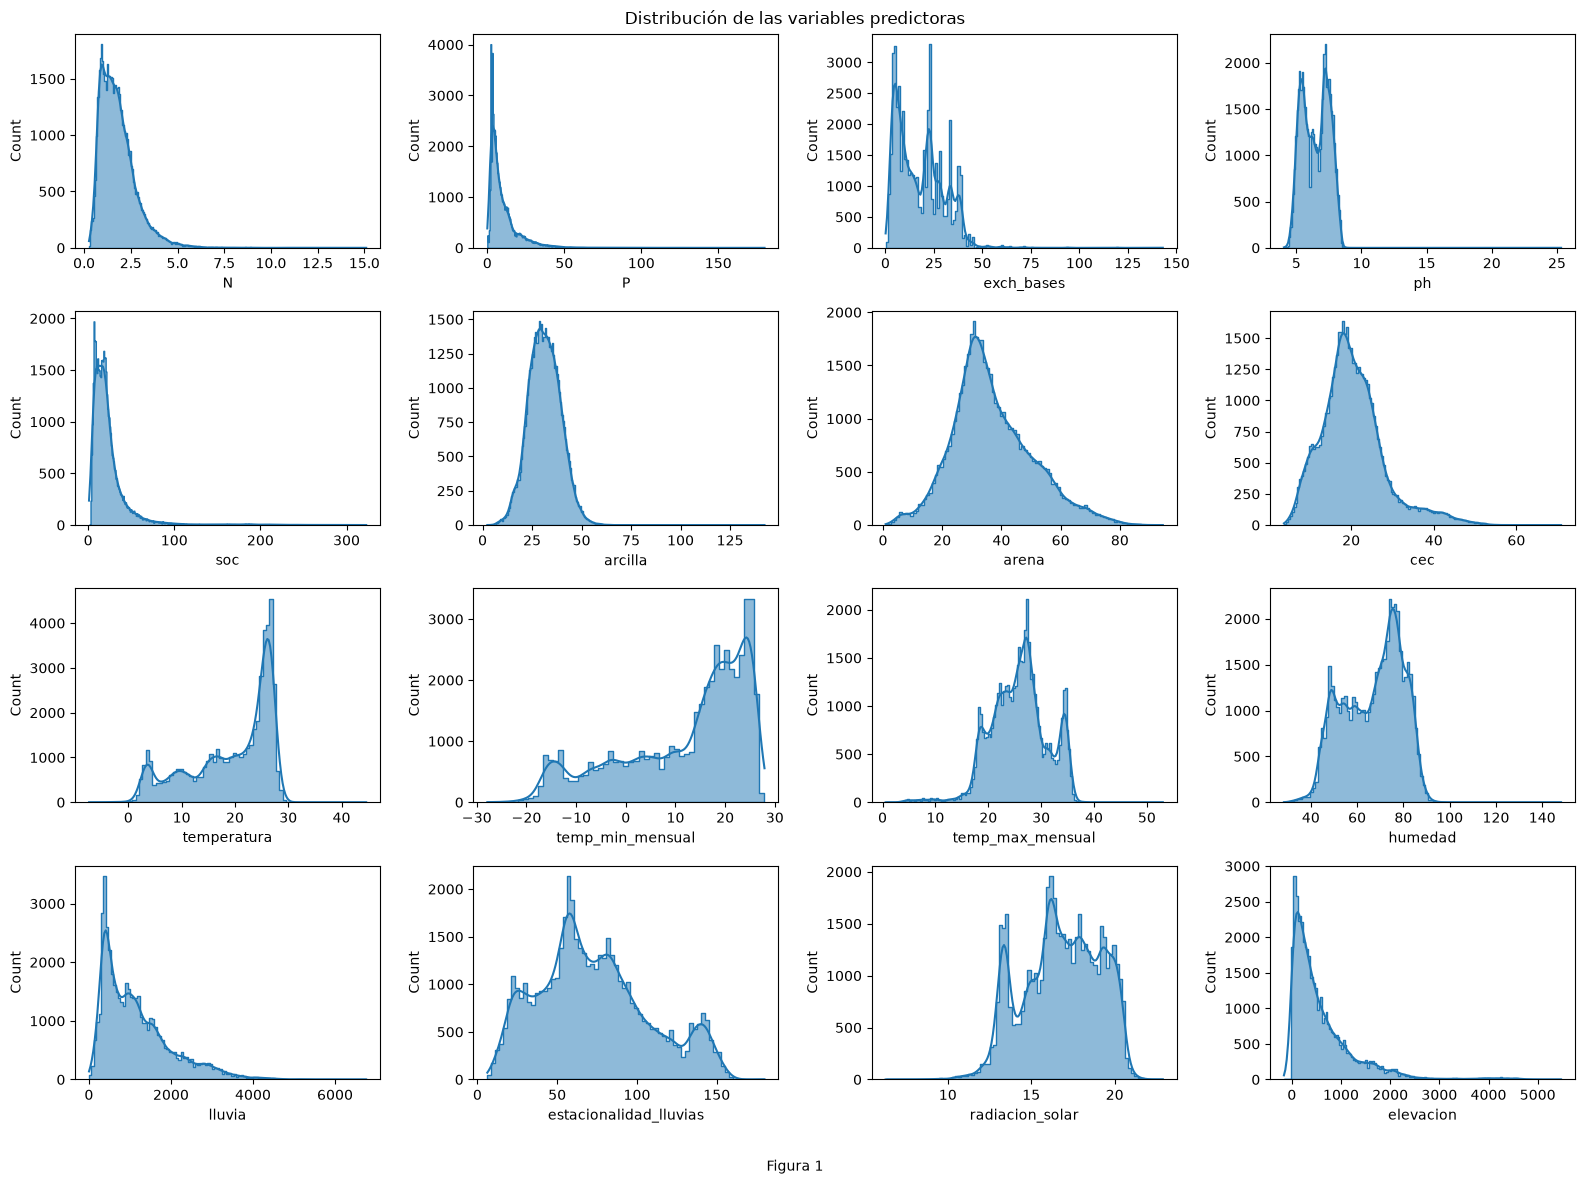

In [4]:
# Grafico la distribución de cada variable predictora
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, element="step", ax=axes.flatten()[i])
plt.suptitle("Distribución de las variables predictoras")
numerar(1)
plt.show()


Figura 1. N, P, soc, lluvia y elevacion se concentran cerca de cero con una cola larga hacia la derecha: P tiene mediana 6.67 y máximo 180, y soc tiene mediana 18.12 y máximo 322.82. temperatura y temp_min_mensual acumulan la mayor parte de los datos en valores altos, con picos cerca de 26 °C y de 25 °C, y una cola hacia valores bajos. ph tiene dos picos, cerca de 5.4 y 7.5, y su eje se estira hasta 25 por dos valores aislados. exch_bases y radiacion_solar también tienen varios picos. Los picos múltiples sugieren que los cultivos ocupan rangos distintos de cada variable, aunque la figura no separa por clase y no lo comprueba.

,Cantidad,Porcentaje
clase,,
cafe,5002,10.0
arroz,5001,10.0
manzana,5001,10.0
maiz,5000,10.0
garbanzo,5000,10.0
algodon,5000,10.0
banana,5000,10.0
frijol,5000,10.0
coco,5000,10.0


Razón clase mayoritaria / minoritaria: 1.0


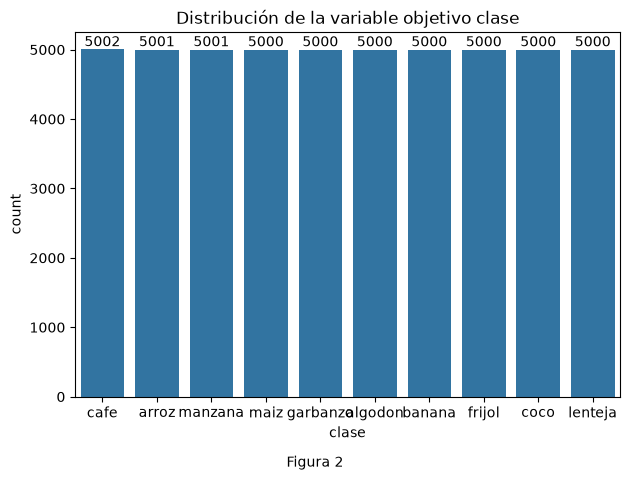

In [5]:
# Miro el balance de la variable objetivo clase
cantidad = df["clase"].value_counts()
balance = pd.DataFrame({"Cantidad": cantidad, "Porcentaje": (cantidad / len(df) * 100).round(2)})
display(balance)
print("Razón clase mayoritaria / minoritaria:", round(cantidad.max() / cantidad.min(), 3))

ax = sns.countplot(data=df, x="clase", order=cantidad.index)
ax.bar_label(ax.containers[0])
plt.title("Distribución de la variable objetivo clase")
numerar(2)
plt.show()


Figura 2. Las 10 clases tienen 5000 filas cada una, salvo cafe (5002), arroz (5001) y manzana (5001). La razón entre la clase mayoritaria y la minoritaria es 1.0. El enunciado menciona un leve desbalance que el archivo original no tiene: aparece recién al eliminar los duplicados.

Hipótesis: esperamos que las tres variables de temperatura estén muy correlacionadas.

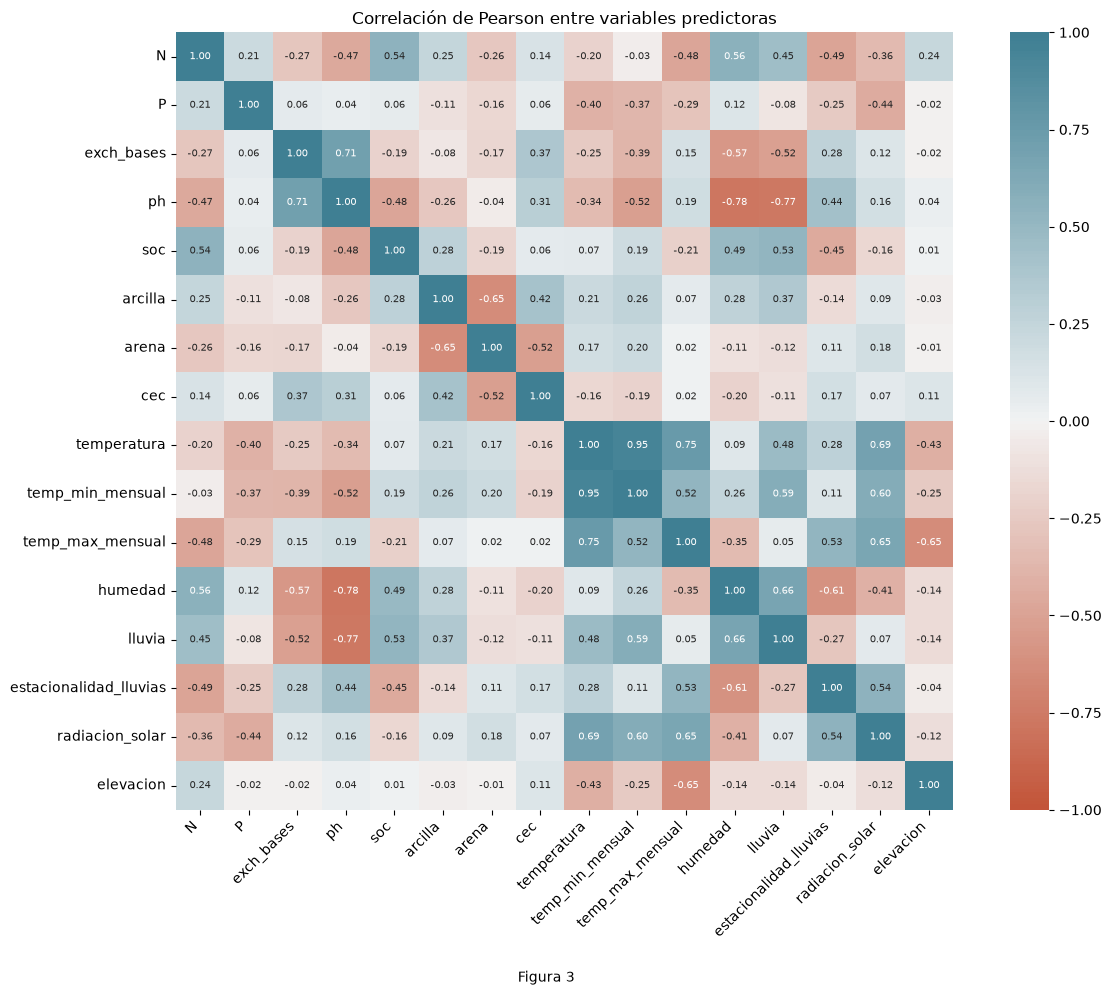

In [6]:
# Grafico la matriz de correlación de Pearson entre las variables predictoras
corr = df[num_cols].corr(method="pearson")
plt.figure(figsize=(13, 10))
ax = sns.heatmap(corr, vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(20, 220, n=200),
                 square=True, annot=True, fmt=".2f", annot_kws={"size": 7})
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment="right")
plt.title("Correlación de Pearson entre variables predictoras")
numerar(3)
plt.show()


Figura 3. temperatura se relaciona con temp_min_mensual (0.95) y con temp_max_mensual (0.75), pero temp_min_mensual y temp_max_mensual solo llegan a 0.52 entre sí. La hipótesis sobre las temperaturas se cumple en parte. ph tiene correlación negativa alta con humedad (-0.78) y con lluvia (-0.77), y positiva con exch_bases (0.71). arcilla y arena están en oposición (-0.65), y temp_max_mensual con elevacion también (-0.65).

Hay varias variables redundantes. No eliminamos ninguna, porque la consigna no pide selección de variables y el SVM y el Random Forest toleran predictoras correlacionadas. En el Random Forest la importancia se reparte entre las variables correlacionadas, así que hay que leerla con cuidado.

### (a) Valores faltantes

In [7]:
# (a) Valores faltantes: muestro la fila que los contiene
display(df[df.isna().any(axis=1)])


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25085,2.773,3.891,3.8,NaN,33.017,31.333,48.217,NaN,19.355,15.852,22.09,NaN,1294,63.371,14.632,769,cafe


Los 3 nulos están en una sola fila (índice 25085, clase cafe): le faltan ph, cec y humedad. Eliminamos la fila. Es 1 de 50004 filas (0.002%) y cafe tiene 5002. Imputar con la media o la mediana reemplazaría 3 de sus 16 valores por constantes que no vienen de ninguna medición.

### (b) Registros duplicados

In [8]:
# (b) Registros duplicados: cuento cuántos hay por clase
print("Filas duplicadas:", df.duplicated().sum())
print(df[df.duplicated()]["clase"].value_counts().to_string())


Filas duplicadas: 198
clase
lenteja     109
manzana      55
algodon      14
garbanzo     12
maiz          3
frijol        3
arroz         2


Hay 198 filas duplicadas: 109 de lenteja, 55 de manzana, 14 de algodon, 12 de garbanzo, 3 de maiz, 3 de frijol y 2 de arroz. Eliminamos las copias y dejamos la primera aparición. En validación cruzada una copia en train y otra en test deja un ejemplo ya visto en el test, y las métricas salen infladas.

### (c) Posibles outliers

In [9]:
# (c) Atípicos: cuento los valores fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR] en cada variable
filas = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    filas.append({"Variable": col, "Atípicos": n, "Porcentaje": round(n / len(df) * 100, 1),
                  "Mínimo": df[col].min(), "Máximo": df[col].max()})
display(pd.DataFrame(filas).set_index("Variable"))

# Busco los valores imposibles: pH mayor que 14, humedad relativa mayor que 100 % y arcilla mayor que 100 %
imposibles = (df["ph"] > 14) | (df["humedad"] > 100) | (df["arcilla"] > 100)
display(df[imposibles])


,Atípicos,Porcentaje,Mínimo,Máximo
Variable,,,,
N,1483,3.0,0.265,15.098
P,3453,6.9,0.000,180.000
exch_bases,181,0.4,0.100,143.000
ph,2,0.0,4.050,25.317
soc,3665,7.3,1.017,322.817
arcilla,292,0.6,2.400,142.383
arena,849,1.7,0.883,94.500
cec,2162,4.3,3.717,70.817
temperatura,14,0.0,-7.377,44.626


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25111,10.970,3.000,0.1,25.317,16.633,33.850,53.317,13.133,23.500,21.909,24.918,82.018,17,61.612,13.901,679,cafe
30012,0.648,6.599,26.6,18.017,4.967,142.383,68.633,17.683,44.626,6.145,53.006,148.141,265,28.815,6.274,322,manzana


Por el criterio del IQR, las variables con más atípicos son soc (3665, 7.3%), P (3453, 6.9%), elevacion (2825, 5.6%), cec (2162, 4.3%), N (1483, 3.0%) y lluvia (1360, 2.7%). Todas tienen cola derecha en la Figura 1. Una precipitación, una altura o un contenido de carbono grandes son valores posibles, así que los conservamos.

Dos filas tienen valores imposibles. La fila 25111 (cafe) tiene ph de 25.317. La fila 30012 (manzana) tiene ph de 18.017, arcilla de 142.383 y humedad de 148.141, y además temperatura de 44.626 y temp_max_mensual de 53.006, los máximos de esas dos columnas. Las eliminamos.

In [10]:
# Elimino las filas imposibles, los duplicados y la fila con nulos
df_clean = df[~imposibles].drop_duplicates().dropna()
print("Filas:", len(df), "->", len(df_clean), "| eliminadas:", len(df) - len(df_clean))

cantidad = df_clean["clase"].value_counts()
display(pd.DataFrame({"Cantidad": cantidad, "Porcentaje": (cantidad / len(df_clean) * 100).round(2)}))
print("Razón clase mayoritaria / minoritaria:", round(cantidad.max() / cantidad.min(), 3))


Filas: 50004 -> 49803 | eliminadas: 201


,Cantidad,Porcentaje
clase,,
banana,5000,10.04
cafe,5000,10.04
coco,5000,10.04
arroz,4999,10.04
maiz,4997,10.03
frijol,4997,10.03
garbanzo,4988,10.02
algodon,4986,10.01
manzana,4945,9.93


Razón clase mayoritaria / minoritaria: 1.022


Filtramos antes las 2 filas con valores imposibles, y después eliminamos los duplicados y la fila con nulos.

El conjunto pasa de 50004 a 49803 filas. Las 201 filas eliminadas son las 198 duplicadas, la fila con nulos y las 2 con valores imposibles.

Después de limpiar, las clases quedan entre 4891 (lenteja) y 5000 (banana, cafe y coco), con razón de 1.022. Lenteja y manzana (4945) perdieron filas por los duplicados. Es un desbalance leve, y por eso usamos Precision y Recall con promedio weighted, como pide la consigna.

In [11]:
# Codifico clase como enteros de 0 a 9 (orden alfabético)
le = LabelEncoder()
y = le.fit_transform(df_clean["clase"])
X = df_clean.drop(columns="clase")
print(dict(enumerate(le.classes_)))

# Estandarizo las predictoras con StandardScaler y verifico media 0 y desvío 1
X_std = StandardScaler().set_output(transform="pandas").fit_transform(X)
display(X_std.describe().loc[["mean", "std"]].round(3))


{0: 'algodon', 1: 'arroz', 2: 'banana', 3: 'cafe', 4: 'coco', 5: 'frijol', 6: 'garbanzo', 7: 'lenteja', 8: 'maiz', 9: 'manzana'}


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion
mean,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


LabelEncoder codifica la variable objetivo en orden alfabético: algodon es 0 y manzana es 9. SVC y RandomForestClassifier aceptan etiquetas de texto, pero la consigna pide codificar. Las matrices de confusión de la Actividad 5 recuperan los nombres con le.classes_.

La tabla muestra media 0 y desvío 1 en las 16 variables. X_std sirve solo para esta verificación y para la Figura 4. Las diapositivas de la U4 indican estandarizar después de separar los datos, con la media y el desvío de entrenamiento, para evitar la fuga de datos. Por eso, en las Actividades 2 y 3 el StandardScaler va dentro de un make_pipeline, que lo ajusta solo con los 4 folds de entrenamiento de cada partición. El Random Forest usa X sin estandarizar, porque no depende de la escala.

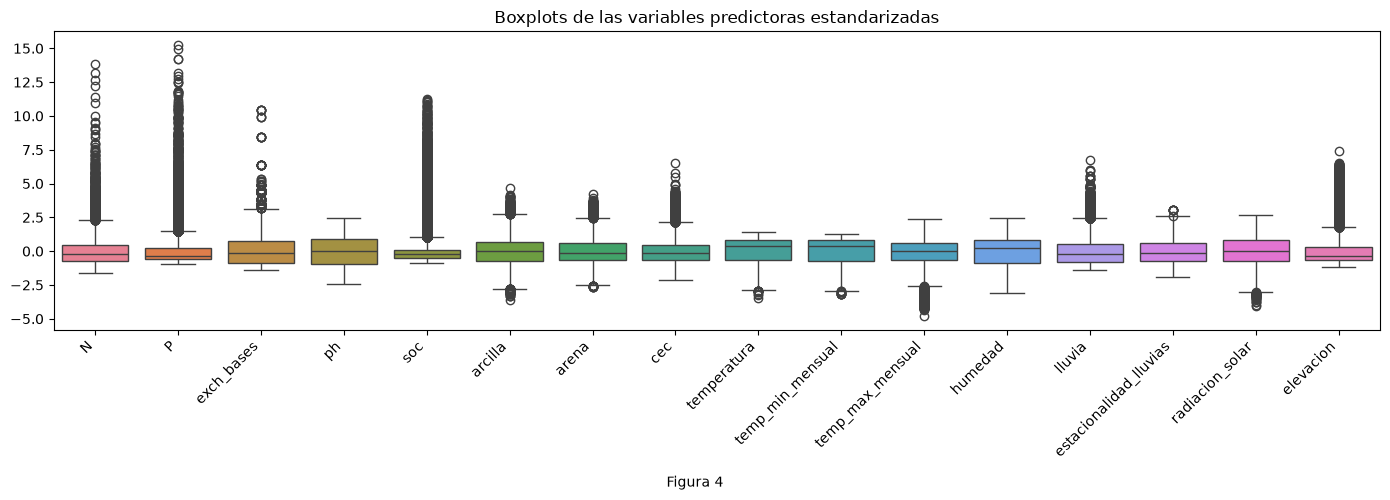

In [12]:
# Grafico los boxplots de las variables estandarizadas para ver los atípicos que conservamos
plt.figure(figsize=(14, 5))
sns.boxplot(data=X_std)
plt.xticks(rotation=45, ha="right")
plt.title("Boxplots de las variables predictoras estandarizadas")
numerar(4)
plt.show()


Figura 4. Los atípicos que conservamos se ven en la escala estandarizada: P llega a 15.3 desvíos, N a 13.8, soc a 11.3, exch_bases a 10.4, elevacion a 7.4 y lluvia a 6.7. ph y humedad no tienen puntos fuera de las barras, ya sin las dos filas imposibles. temperatura, temp_min_mensual, temp_max_mensual y radiacion_solar solo tienen atípicos por debajo. Estas colas entran tal cual en los modelos. Coincide con la hipótesis inicial: P, soc, lluvia y elevacion tienen colas largas a la derecha.

## 2. SVM con kernel lineal

Exploramos C en 0.01, 0.1, 1, 10 y 100 con SVC(kernel="linear"). Cada valor se evalúa con validación cruzada estratificada de 5 folds sobre las 49803 filas limpias, con el StandardScaler dentro del pipeline. Reportamos media y desvío de Precision weighted, Recall weighted y Accuracy. Elegimos la configuración más rápida entre las que quedan a un desvío de la mejor Accuracy media.

Hipótesis: esperamos una Accuracy moderada y poca mejora con C, porque los cultivos se solapan (Figura 1).

In [13]:
# Defino la validación cruzada estratificada de 5 folds y las tres métricas
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"precision": "precision_weighted", "recall": "recall_weighted", "accuracy": "accuracy"}


# Defino una función que arma la tabla de resultados de un GridSearchCV (media y desvío de los 5 folds)
def resumen(grid):
    res = pd.DataFrame(grid.cv_results_)
    params = [c for c in res.columns if c.startswith("param_")]
    out = res[params].rename(columns=lambda c: c.replace("param_svc__", "").replace("param_", ""))
    for m in scoring:
        out[f"{m} media"] = res[f"mean_test_{m}"]
        out[f"{m} std"] = res[f"std_test_{m}"]
    out["tiempo de fit (s)"] = res["mean_fit_time"]
    return out


# REVISAR: no está en los apuntes. refit acepta una función que recibe cv_results_ y devuelve el índice de la configuración elegida
# Defino una función que elige la configuración más rápida entre las que quedan a un desvío de la mejor Accuracy media
def mas_rapida(cv_results):
    res = pd.DataFrame(cv_results)
    mejor = res["mean_test_accuracy"].idxmax()
    umbral = res.loc[mejor, "mean_test_accuracy"] - res.loc[mejor, "std_test_accuracy"]
    return res.loc[res["mean_test_accuracy"] >= umbral, "mean_fit_time"].idxmin()


Definimos una sola validación cruzada y la reutilizamos en las Actividades 2, 3 y 4, así las tres comparaciones usan los mismos folds.

- StratifiedKFold con shuffle=True: el enunciado pide validación cruzada estratificada. El CSV está ordenado por clase (10 bloques seguidos, uno por clase), por eso mezclamos las filas antes de armar los folds.
- scoring como diccionario: calcula en cada fold las tres métricas que pide el enunciado. En la práctica de la U5, GridSearchCV usa una sola (scoring="accuracy").
- mean_fit_time: tiempo medio de entrenamiento por fold. Es una columna de cv_results_, la tabla que la práctica de la U5 pasa a un DataFrame. Lo usamos en mas_rapida y en la Actividad 5. Los 5 folds corren en paralelo (n_jobs=-1), así que los tiempos sirven para comparar configuraciones y modelos entre sí.
- refit con la función mas_rapida: no figura en los apuntes. Entre las configuraciones que quedan a un desvío de la mejor Accuracy media, elige la de menor tiempo de entrenamiento. Las diferencias dentro de un desvío no se distinguen de la variación entre folds, y el tiempo es uno de los criterios de la Actividad 5.

In [14]:
# Busco C con GridSearchCV sobre todo el conjunto limpio; el StandardScaler va dentro del pipeline
grid_lineal = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="linear", random_state=SEED)),
                           {"svc__C": [0.01, 0.1, 1, 10, 100]},
                           cv=skf, scoring=scoring, refit=mas_rapida, n_jobs=-1)
grid_lineal.fit(X, y)
res_lineal = resumen(grid_lineal)
display(res_lineal.round(4))
print("Configuración elegida:", grid_lineal.best_params_)


,C,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
0,0.01,0.6048,0.0044,0.6048,0.0036,0.6048,0.0036,48.7069
1,0.10,0.6172,0.0056,0.6179,0.0050,0.6179,0.0050,51.8352
2,1.00,0.6219,0.0052,0.6219,0.0049,0.6219,0.0049,96.9579
3,10.00,0.6230,0.0049,0.6230,0.0047,0.6230,0.0047,186.0891
4,100.00,0.6232,0.0050,0.6232,0.0047,0.6232,0.0047,673.1279


Configuración elegida: {'svc__C': 1}


Resultados: la Accuracy media es 0.6048 con C=0.01, 0.6179 con C=0.1, 0.6219 con C=1, 0.6230 con C=10 y 0.6232 con C=100. Precision y Recall weighted quedan casi iguales a la Accuracy, con desvíos entre 0.0036 y 0.0056.

La Accuracy media más alta es la de C=100 (0.6232 ± 0.0047). C=1 y C=10 quedan dentro de ese desvío (0.6219 y 0.6230), y C=0.1 queda fuera (0.6179). Entre esas tres elegimos C=1, que entrena en 97 s por fold contra 186 s con C=10 y 673 s con C=100. Su Accuracy es 0.6219 ± 0.0049, su Precision 0.6219 ± 0.0052 y su Recall 0.6219 ± 0.0049.

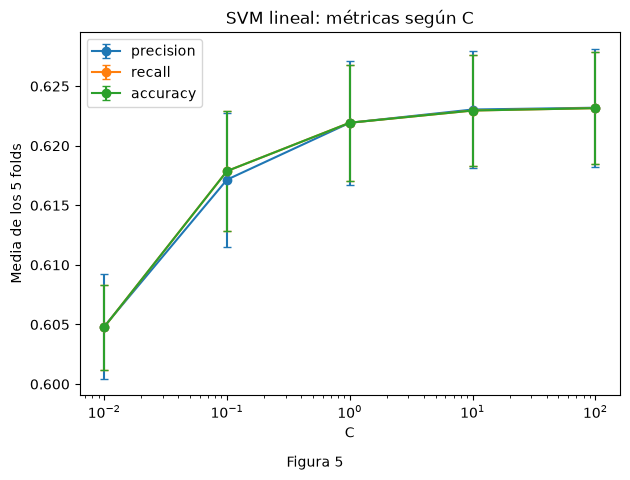

In [15]:
# Grafico las tres métricas medias con su desvío en función de C
for m in scoring:
    plt.errorbar(res_lineal["C"], res_lineal[f"{m} media"], yerr=res_lineal[f"{m} std"],
                 marker="o", capsize=3, label=m)
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Media de los 5 folds")
plt.title("SVM lineal: métricas según C")
plt.legend()
numerar(5)
plt.show()


Figura 5. La Accuracy sube de 0.6048 (C=0.01) a 0.6219 (C=1) y se aplana: de 1 a 100 gana solo 0.0013. Las tres métricas se superponen y las barras de error cubren las diferencias entre C=1, 10 y 100. Toda la curva se mueve en un rango de 0.0184 (de 0.6048 a 0.6232). Coincide con la hipótesis: la Accuracy ronda 0.62 y C cambia poco el resultado, así que el límite lo pone la frontera lineal.

## 3. SVM con kernel gaussiano (RBF)

Probamos C en 0.1, 1, 10 y 100, y gamma en 0.001, 0.01, 0.1 y 1 (16 combinaciones y 80 entrenamientos), con el mismo StratifiedKFold y el mismo pipeline.

Hipótesis: esperamos que el RBF supere al lineal y que subajuste con gamma chico.

In [16]:
# Busco C y gamma con GridSearchCV (16 combinaciones) sobre todo el conjunto limpio
param_rbf = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}
grid_rbf = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=SEED)),
                        param_rbf, cv=skf, scoring=scoring, refit=mas_rapida, n_jobs=-1)
grid_rbf.fit(X, y)
res_rbf = resumen(grid_rbf)
display(res_rbf.sort_values("accuracy media", ascending=False).round(4))
print("Configuración elegida:", grid_rbf.best_params_)


,C,gamma,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
11,10.0,1.000,0.8881,0.0033,0.8864,0.0035,0.8864,0.0035,88.3177
14,100.0,0.100,0.8841,0.0018,0.8850,0.0018,0.8850,0.0018,32.8304
7,1.0,1.000,0.8834,0.0029,0.8812,0.0029,0.8812,0.0029,86.8444
15,100.0,1.000,0.8826,0.0023,0.8805,0.0027,0.8805,0.0027,59.9980
10,10.0,0.100,0.8678,0.0038,0.8688,0.0038,0.8688,0.0038,25.6362
6,1.0,0.100,0.8239,0.0032,0.8244,0.0034,0.8244,0.0034,27.4533
13,100.0,0.010,0.8054,0.0039,0.8061,0.0039,0.8061,0.0039,43.1780
3,0.1,1.000,0.8271,0.0055,0.7611,0.0063,0.7611,0.0063,100.0382
9,10.0,0.010,0.7516,0.0062,0.7510,0.0059,0.7510,0.0059,35.3419
2,0.1,0.100,0.7421,0.0043,0.7413,0.0046,0.7413,0.0046,44.5997


Configuración elegida: {'svc__C': 100, 'svc__gamma': 0.1}


La Accuracy media más alta es la de C=10 y gamma=1 (0.8864 ± 0.0035). Dentro de ese desvío queda también C=100 con gamma=0.1 (0.8850), y C=1 con gamma=1 (0.8812) queda fuera. Elegimos C=100 y gamma=0.1: entrena en 33 s por fold contra 88 s, y tiene el menor desvío de la tabla (0.0018). Su Accuracy es 0.8850 ± 0.0018, su Precision 0.8841 ± 0.0018 y su Recall 0.8850 ± 0.0018.

C=100 está en el borde de la grilla, igual que el gamma de mejor media (1). Valores mayores podrían rendir algo más. No los probamos porque la grilla pedida llega hasta esos valores.

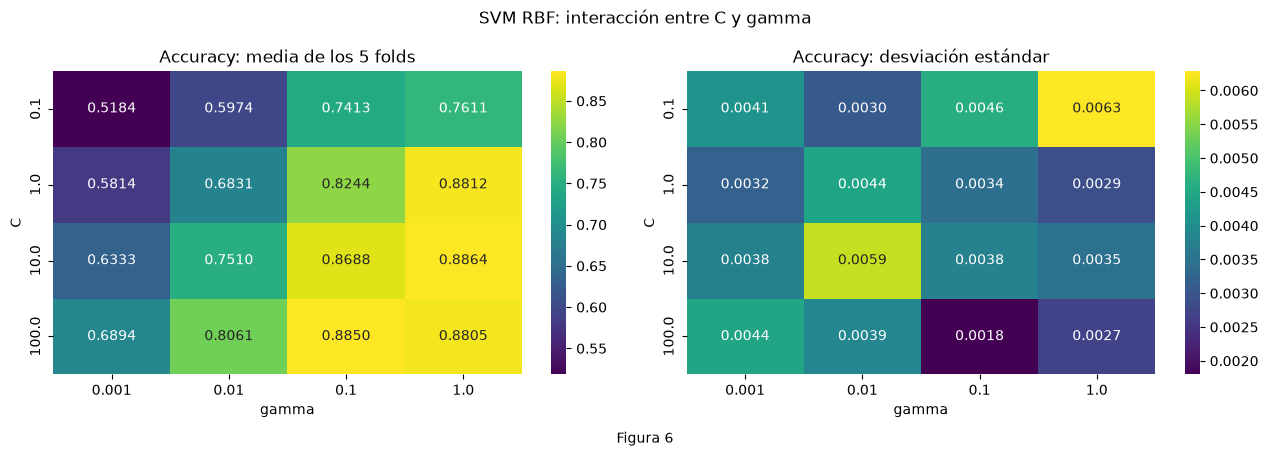

In [17]:
# Grafico la media y el desvío de la Accuracy según C y gamma
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (col, titulo) in zip(axes, [("accuracy media", "Accuracy: media de los 5 folds"),
                                    ("accuracy std", "Accuracy: desviación estándar")]):
    sns.heatmap(res_rbf.pivot(index="C", columns="gamma", values=col), annot=True, fmt=".4f", cmap="viridis", ax=ax)
    ax.set_title(titulo)
plt.suptitle("SVM RBF: interacción entre C y gamma")
numerar(6)
plt.show()


El mapa de calor necesita C en las filas y gamma en las columnas, por eso la tabla de resultados pasa por pivot.

Figura 6. Con C=0.1 la Accuracy va de 0.5184 (gamma=0.001) a 0.7611 (gamma=1). Con gamma=0.001 no pasa de 0.6894 aunque C llegue a 100, y esa columna subajusta, como esperábamos. La zona con C de 1 en adelante y gamma de 0.1 en adelante concentra los valores altos, entre 0.8244 y 0.8864. Con gamma=1 el aumento de C se frena: de C=10 a C=100 la Accuracy baja de 0.8864 a 0.8805. El mapa del desvío va de 0.0018 (C=100, gamma=0.1) a 0.0063 (C=0.1, gamma=1).

El RBF elegido (0.8850) supera al lineal elegido (0.6219) por 0.2631, y la hipótesis se cumple.

## 4. Random Forest

Probamos n_estimators en 50, 100, 200 y 500, y max_depth en 5, 10, 20 y None (16 combinaciones y 80 entrenamientos), con el mismo StratifiedKFold. El Random Forest se entrena con X sin estandarizar.

Hipótesis: según las diapositivas de la U6, agregar árboles estabiliza el error, pero demasiados árboles vuelven el modelo ineficiente. Esperamos que max_depth pese más que n_estimators y que el Random Forest supere al RBF.

In [18]:
# Busco n_estimators y max_depth con GridSearchCV (16 combinaciones); Random Forest se entrena sin estandarizar
param_rf = {"n_estimators": [50, 100, 200, 500], "max_depth": [5, 10, 20, None]}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=SEED), param_rf,
                       cv=skf, scoring=scoring, refit=mas_rapida, n_jobs=-1)
grid_rf.fit(X, y)
res_rf = resumen(grid_rf)
display(res_rf.sort_values("accuracy media", ascending=False).round(4))
print("Configuración elegida:", grid_rf.best_params_)


,max_depth,n_estimators,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
15,None,500,0.9162,0.0035,0.9167,0.0035,0.9167,0.0035,67.1657
14,None,200,0.9149,0.0037,0.9154,0.0037,0.9154,0.0037,33.1634
13,None,100,0.9144,0.0031,0.9149,0.0031,0.9149,0.0031,16.9856
11,20,500,0.9138,0.0038,0.9141,0.0038,0.9141,0.0038,78.2320
10,20,200,0.9133,0.0035,0.9137,0.0035,0.9137,0.0035,33.9415
12,None,50,0.9131,0.0036,0.9137,0.0036,0.9137,0.0036,8.8612
9,20,100,0.9119,0.0028,0.9124,0.0029,0.9124,0.0029,16.4990
8,20,50,0.9101,0.0033,0.9105,0.0033,0.9105,0.0033,8.1827
7,10,500,0.8458,0.0045,0.8430,0.0047,0.8430,0.0047,57.7347
6,10,200,0.8448,0.0046,0.8422,0.0048,0.8422,0.0048,22.3889


Configuración elegida: {'max_depth': None, 'n_estimators': 50}


La Accuracy media más alta es la de max_depth=None y 500 árboles (0.9167 ± 0.0035). Seis configuraciones quedan dentro de ese desvío, todas con max_depth de 20 o None. Elegimos max_depth=None y 50 árboles: llega a 0.9137 ± 0.0036 y entrena en 9 s por fold, contra 67 s de la de 500. Su Precision es 0.9131 ± 0.0036 y su Recall 0.9137 ± 0.0036.

max_depth pesa mucho: con 5 la Accuracy está entre 0.6385 y 0.6456, con 10 entre 0.8394 y 0.8430, y con 20 o None entre 0.9105 y 0.9167. n_estimators pesa poco: con max_depth=None, pasar de 50 a 500 árboles sube la Accuracy de 0.9137 a 0.9167, una diferencia de 0.0030 menor que el desvío (0.0035).

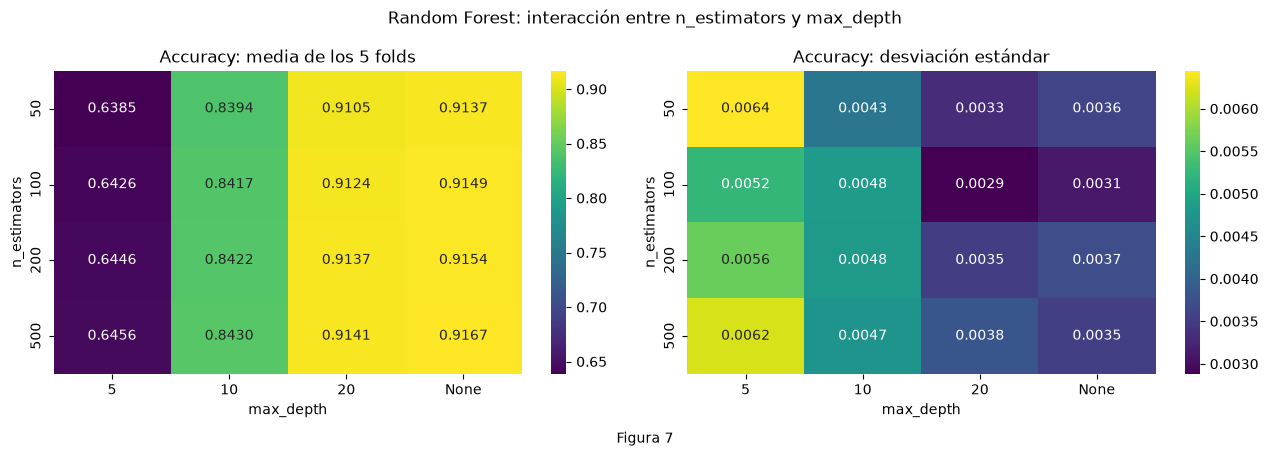

In [19]:
# Grafico la media y el desvío de la Accuracy según n_estimators y max_depth
res_rf["max_depth"] = res_rf["max_depth"].map(str)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (col, titulo) in zip(axes, [("accuracy media", "Accuracy: media de los 5 folds"),
                                    ("accuracy std", "Accuracy: desviación estándar")]):
    sns.heatmap(res_rf.pivot(index="n_estimators", columns="max_depth", values=col)[["5", "10", "20", "None"]],
                annot=True, fmt=".4f", cmap="viridis", ax=ax)
    ax.set_title(titulo)
plt.suptitle("Random Forest: interacción entre n_estimators y max_depth")
numerar(7)
plt.show()


Este mapa también pasa por pivot. max_depth se pasa a texto con map(str) para que None quede como columna del mapa.

Figura 7. La Accuracy cambia sobre todo por filas de max_depth: de 5 a 10 sube cerca de 0.20 (0.6456 a 0.8430 con 500 árboles) y de 10 a 20 cerca de 0.07 (0.8430 a 0.9141). Entre 20 y None casi no hay cambio. Dentro de cada columna con max_depth de 10 en adelante, n_estimators mueve la Accuracy 0.0036 o menos. El mapa del desvío va de 0.0029 a 0.0064, con los valores más altos en max_depth=5. La hipótesis sobre max_depth y n_estimators se cumple.

Hipótesis: esperamos que las variables de clima y ubicación superen a las de suelo en importancia.

,features,importances
9,temp_min_mensual,0.1100
8,temperatura,0.0899
12,lluvia,0.0898
14,radiacion_solar,0.0886
10,temp_max_mensual,0.0882
11,humedad,0.0879
13,estacionalidad_lluvias,0.0740
15,elevacion,0.0720
3,ph,0.0413
7,cec,0.0410


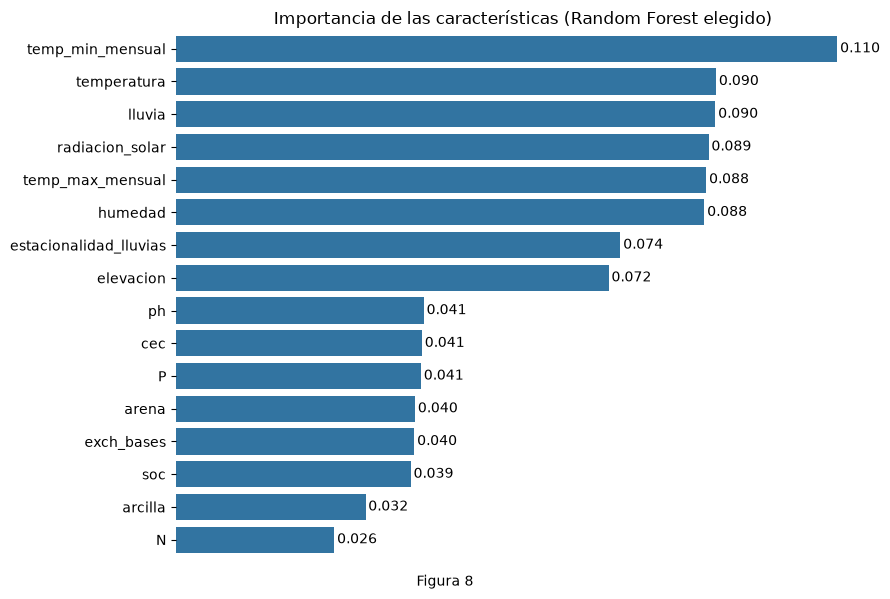

In [20]:
# Armo una tabla con la importancia de cada variable en el Random Forest elegido y la grafico
importancias = pd.DataFrame({"features": X.columns, "importances": grid_rf.best_estimator_.feature_importances_})
importancias = importancias.sort_values(by="importances", ascending=False)
display(importancias.round(4))

plt.figure(figsize=(9, 6))
g = sns.barplot(data=importancias, x="importances", y="features")
sns.despine(bottom=True, left=True)
g.set_title("Importancia de las características (Random Forest elegido)")
g.set(xlabel=None, ylabel=None, xticks=[])
for value in g.containers:
    g.bar_label(value, padding=2, fmt="%.3f")
numerar(8)
plt.show()


Importancias del Random Forest elegido (max_depth=None y 50 árboles, reentrenado con todos los datos): temp_min_mensual 0.1100, temperatura 0.0899, lluvia 0.0898, radiacion_solar 0.0886, temp_max_mensual 0.0882, humedad 0.0879, estacionalidad_lluvias 0.0740 y elevacion 0.0720. Las 8 variables de clima y ubicación suman 0.70 y las 8 de suelo 0.30. En suelo, la mayor es ph (0.0413) y la menor N (0.0264). La hipótesis se cumple.

Figura 8. Las barras repiten la tabla: las ocho primeras son de clima o ubicación y ninguna de suelo supera 0.0413. Todas las variables aportan al menos 0.0264. temperatura y temp_min_mensual tienen correlación de 0.95 (Figura 3), así que la importancia se reparte entre ellas y el orden entre ambas es poco confiable.

## 5. Comparación de modelos

La tabla reúne la configuración elegida de cada algoritmo en las Actividades 2 a 4, con media y desvío de los 5 folds y el tiempo medio de entrenamiento por fold. Para las matrices de confusión usamos el primer fold de la validación cruzada: entrenamos cada configuración elegida con los otros 4 folds y predecimos ese fold.

Hipótesis: la Accuracy en el primer fold queda cerca de la media de validación cruzada, y el lineal confunde más clases que los otros dos.

In [21]:
# Armo la tabla comparativa con la mejor configuración de cada algoritmo
grids = {"SVM lineal": grid_lineal, "SVM RBF": grid_rbf, "Random Forest": grid_rf}
columnas = ["precision media", "precision std", "recall media", "recall std",
            "accuracy media", "accuracy std", "tiempo de fit (s)"]
comparacion = pd.DataFrame({nombre: resumen(g).loc[g.best_index_, columnas] for nombre, g in grids.items()}).T
comparacion.insert(0, "configuración", [g.best_params_ for g in grids.values()])
display(comparacion.round(4))


,configuración,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
SVM lineal,{'svc__C': 1},0.6219,0.0052,0.6219,0.0049,0.6219,0.0049,96.9579
SVM RBF,"{'svc__C': 100, 'svc__gamma': 0.1}",0.8841,0.0018,0.8850,0.0018,0.8850,0.0018,32.8304
Random Forest,"{'max_depth': None, 'n_estimators': 50}",0.9131,0.0036,0.9137,0.0036,0.9137,0.0036,8.8612


Resultados de la validación cruzada (Precision weighted, Recall weighted y Accuracy, media ± desvío):

- SVM lineal (C=1): 0.6219 ± 0.0052, 0.6219 ± 0.0049 y 0.6219 ± 0.0049, con 97 s de entrenamiento por fold.
- SVM RBF (C=100, gamma=0.1): 0.8841 ± 0.0018, 0.8850 ± 0.0018 y 0.8850 ± 0.0018, con 33 s.
- Random Forest (max_depth=None, 50 árboles): 0.9131 ± 0.0036, 0.9137 ± 0.0036 y 0.9137 ± 0.0036, con 9 s.

El Random Forest supera al RBF por 0.0287 de Accuracy, casi ocho veces su desvío (0.0036), y el RBF supera al lineal por 0.2631. El RBF es el más estable entre folds (0.0018), seguido por el Random Forest (0.0036) y el lineal (0.0049).

In [ ]:
# REVISAR: no está en los apuntes. next(skf.split(X, y)) devuelve las posiciones de entrenamiento y de prueba del primer fold
# Armo la configuración elegida de cada algoritmo, la entreno con 4 folds, predigo el primer fold y grafico sus matrices de confusión
entrena, prueba = next(skf.split(X, y))
modelos = {
    "SVM lineal (C=1)": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1, random_state=SEED)),
    "SVM RBF (C=100, gamma=0.1)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=100, gamma=0.1, random_state=SEED)),
    "Random Forest (max_depth=None, 50 árboles)": RandomForestClassifier(n_estimators=50, max_depth=None, random_state=SEED),
}
fig, axes = plt.subplots(1, 3, figsize=(27, 8))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    pred = modelo.fit(X.iloc[entrena], y[entrena]).predict(X.iloc[prueba])
    cm = confusion_matrix(y[prueba], pred)
    ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(f"{nombre}: accuracy en el primer fold = {accuracy_score(y[prueba], pred):.4f}")
plt.suptitle("Matrices de confusión de la configuración elegida de cada algoritmo (primer fold de la validación cruzada)")
numerar(9)
plt.show()


Figura 9. El primer fold tiene 9961 filas, entre 978 y 1000 por clase. La Accuracy es 0.6188 (lineal), 0.8851 (RBF) y 0.9111 (Random Forest). Las tres quedan dentro de un desvío de su media de validación cruzada, y la primera parte de la hipótesis se cumple.

El lineal confunde más clases, y la segunda parte también se cumple. Su Recall por clase va de 0.391 (maiz) a 0.899 (lenteja). Sus mayores confusiones son banana como cafe (205), algodon como frijol (191) y cafe como coco (169). El RBF y el Random Forest tienen la diagonal mucho más marcada.

maiz es la clase más difícil en los tres modelos, con Recall de 0.391, 0.728 y 0.767. En el RBF, maiz se predice como algodon 57 veces y como arroz 51. En el Random Forest sus errores se reparten entre arroz (40), manzana (35) y algodon (34). garbanzo se predice como lenteja 49 veces en el RBF y 50 en el Random Forest. El Random Forest acierta más que el RBF en las diez clases, aunque en lenteja la diferencia es de un caso (954 contra 953).

Elegimos el Random Forest:

- Tiene las mejores métricas: Accuracy de 0.9137 en validación cruzada, contra 0.8850 del RBF y 0.6219 del lineal.
- Su desvío (0.0036) duplica el del RBF (0.0018), pero es chico frente a la diferencia de 0.0287 entre ambos. El lineal tiene 0.0049.
- Entrena en 9 s por fold, contra 33 s del RBF y 97 s del lineal.
- Entrega la importancia de las variables (Figura 8). Las diapositivas de la U6 cuentan esa estimación entre las ventajas del Random Forest, y las de la U5 señalan que un SVM con kernel no lineal es difícil de interpretar.

El lineal queda descartado por su Accuracy de 0.6219. El RBF es la segunda opción y el más estable entre folds.

# Conclusiones

Eliminamos 201 de 50004 filas: 198 duplicadas, una con tres nulos y dos con valores imposibles (por ejemplo, un ph de 25.317). Conservamos los atípicos por IQR, porque son colas largas posibles. El conjunto limpio tiene 49803 filas y un desbalance leve (razón de 1.022), que aparece recién al eliminar duplicados.

Con validación cruzada estratificada de 5 folds, la Accuracy media fue 0.6219 en el SVM lineal (C=1), 0.8850 en el RBF (C=100, gamma=0.1) y 0.9137 en el Random Forest (max_depth=None, 50 árboles). En cada algoritmo elegimos la configuración más rápida dentro de un desvío de la mejor media. Elegimos el Random Forest: supera al RBF por 0.0287, casi ocho veces su desvío, entrena en 9 s por fold contra 33 s y 97 s, y da la importancia de las variables. Las 8 de clima y ubicación suman 0.70 de esa importancia.

Casi todas las hipótesis se cumplieron: colas a la derecha, poca mejora del lineal con C, subajuste del RBF con gamma chico, max_depth por encima de n_estimators y clima por encima de suelo. La de temperaturas se cumplió en parte: temp_min_mensual y temp_max_mensual solo llegan a 0.52 entre sí. En el primer fold, maiz fue la clase más difícil en los tres modelos.

Limitaciones: el RBF elegido queda en el borde de la grilla (C=100), la Figura 9 usa un solo fold, los tiempos se midieron con los folds en paralelo y usamos una sola semilla (13).